#### Exploration of Airline data

### Context
### I decided to look at a business problem faced by Airlines and Airports today - namely flight delays - and examine data to find out what 
### patterns exist in the data that might help top management reduce delays.

### Questions

Question 1: Did fewer flights have long delays than short delays?  
Question 2: How many flights were cancelled and delayed?  
Question 3: What is the correlation (if any) between Departure Delays and Arrival Delays?  
Question 4: What do delays look like by selected airports?

### Data
The data used in this notebook came from this website
https://www.transtats.bts.gov/Fields.asp?gnoyr_VQ=FGJ - I selected only the fields that I thought would be useful for the questions above. 

I will illustrate the shape and structure of the dataset I chose at the url above (to reduce the amount of data I downloaded to only data that was needed for what I was trying to do).  

I will ask questions about the data, and use Python data science and visualization libraries to explore the dataset’s variables and understand the data’s structure,
oddities, patterns, and relationships.

The analysis in this part will be structured, going from simple univariate relationships to multivariate relationships.
I will determine some of the answers that can come out of the Airlines dataset.

This part of the project is my opportunity to ask questions about the data and make discoveries. 
I will be patient with my steps, document my work carefully, and be thorough in the perspective that I choose to take with my dataset.

I must ensure that my code should not generate any errors, and should use functions, loops where possible to reduce 
repetitive code.

I will document my approach and findings in markdown cells. I will use comments and docstrings in code cells to document the
code functionality.

I will ensure my markup cells have headers and text that organize my thoughts, findings, and what I plan on investigating
next.  

## Preliminary Wrangling

In [1]:
# here I import all packages and set plots to be embedded inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


### Describing the dataset

Here I will load in the Airlines dataset and describe its properties through the questions below. 
I will try to motivate my exploration goals through this section.

NOTE!
I have first reduced the amount of data in my dataset file by selecting only the data I wanted.  
I selected only *January 2026 data* and I selected only the columns I think I need to explore as part of this work - including date information, flight information (airline), departure and arrival information, delay information and cancelation information

Below, I load the file and show the number of rows and columns in the file by using df.shape


In [2]:
#import the file and check the number of rows and columns
import pandas as pd
df = pd.read_csv('T_ONTIME_REPORTING.csv')
df.shape 

(544003, 16)

In [3]:
#display the types of each of the 16 columns using dtypes
df.dtypes

YEAR                       int64
QUARTER                    int64
MONTH                      int64
OP_UNIQUE_CARRIER         object
ORIGIN_AIRPORT_ID          int64
ORIGIN_AIRPORT_SEQ_ID      int64
ORIGIN_CITY_MARKET_ID      int64
ORIGIN                    object
ORIGIN_CITY_NAME          object
ORIGIN_STATE_ABR          object
DEST_AIRPORT_ID            int64
DEST_AIRPORT_SEQ_ID        int64
DEST_CITY_MARKET_ID        int64
DEP_DELAY                float64
ARR_DELAY_NEW            float64
CANCELLED                  int64
dtype: object

In [4]:
#show the first 10 rows in the dataset with all columns so we get an idea of the structure of the dataset
#here you can see that above we have 16 columns - some ints some floats and some objects.  Below is a sample of the data in the dataset
df.head(10)

,YEAR,QUARTER,MONTH,OP_UNIQUE_CARRIER,ORIGIN_AIRPORT_ID,ORIGIN_AIRPORT_SEQ_ID,ORIGIN_CITY_MARKET_ID,ORIGIN,ORIGIN_CITY_NAME,ORIGIN_STATE_ABR,DEST_AIRPORT_ID,DEST_AIRPORT_SEQ_ID,DEST_CITY_MARKET_ID,DEP_DELAY,ARR_DELAY_NEW,CANCELLED
0,2026,1,1,AA,10140,1014006,30140,ABQ,"Albuquerque, NM",NM,11298,1129806,30194,NaN,NaN,1
1,2026,1,1,AA,10140,1014006,30140,ABQ,"Albuquerque, NM",NM,11298,1129806,30194,NaN,NaN,1
2,2026,1,1,AA,10140,1014006,30140,ABQ,"Albuquerque, NM",NM,11298,1129806,30194,NaN,NaN,1
3,2026,1,1,AA,10140,1014006,30140,ABQ,"Albuquerque, NM",NM,11298,1129806,30194,NaN,NaN,1
4,2026,1,1,AA,10140,1014006,30140,ABQ,"Albuquerque, NM",NM,11298,1129806,30194,NaN,NaN,1
5,2026,1,1,AA,10140,1014006,30140,ABQ,"Albuquerque, NM",NM,11298,1129806,30194,NaN,NaN,1
6,2026,1,1,AA,10140,1014006,30140,ABQ,"Albuquerque, NM",NM,11298,1129806,30194,NaN,NaN,1
7,2026,1,1,AA,10140,1014006,30140,ABQ,"Albuquerque, NM",NM,11298,1129806,30194,NaN,NaN,1
8,2026,1,1,AA,10140,1014006,30140,ABQ,"Albuquerque, NM",NM,11298,1129806,30194,NaN,NaN,1
9,2026,1,1,AA,10140,1014006,30140,ABQ,"Albuquerque, NM",NM,11298,1129806,30194,NaN,NaN,1


In [5]:
#Find out whether there are nulls in any of the columns
df.info()


<class 'pandas.core.frame.DataFrame'>
,RangeIndex: 544003 entries, 0 to 544002
,Data columns (total 16 columns):
, #   Column                 Non-Null Count   Dtype  
,---  ------                 --------------   -----  
, 0   YEAR                   544003 non-null  int64  
, 1   QUARTER                544003 non-null  int64  
, 2   MONTH                  544003 non-null  int64  
, 3   OP_UNIQUE_CARRIER      544003 non-null  object 
, 4   ORIGIN_AIRPORT_ID      544003 non-null  int64  
, 5   ORIGIN_AIRPORT_SEQ_ID  544003 non-null  int64  
, 6   ORIGIN_CITY_MARKET_ID  544003 non-null  int64  
, 7   ORIGIN                 544003 non-null  object 
, 8   ORIGIN_CITY_NAME       544003 non-null  object 
, 9   ORIGIN_STATE_ABR       544003 non-null  object 
, 10  DEST_AIRPORT_ID        544003 non-null  int64  
, 11  DEST_AIRPORT_SEQ_ID    544003 non-null  int64  
, 12  DEST_CITY_MARKET_ID    544003 non-null  int64  
, 13  DEP_DELAY              518774 non-null  float64
, 14  ARR_DELAY_NEW    

In [6]:
#At first glance of the data I might think there are no nulls in the dataset but 
# actually there are some in DEP_DELAY,
# ARR_DELAY_NEW so I need to delete the nulls
# using describe below to get a picture of the variability of the data in the columns
#and I need to investigate the values in some of these columns like CANCELLED must be 0 or 1
df.describe()

,YEAR,QUARTER,MONTH,ORIGIN_AIRPORT_ID,ORIGIN_AIRPORT_SEQ_ID,ORIGIN_CITY_MARKET_ID,DEST_AIRPORT_ID,DEST_AIRPORT_SEQ_ID,DEST_CITY_MARKET_ID,DEP_DELAY,ARR_DELAY_NEW,CANCELLED
count,544003.0,544003.0,544003.0,544003.000000,5.440030e+05,544003.000000,544003.000000,5.440030e+05,544003.00000,518774.000000,517222.000000,544003.000000
mean,2026.0,1.0,1.0,12680.789312,1.268083e+06,31748.369825,12680.593587,1.268064e+06,31748.29341,13.096535,16.640533,0.047123
std,0.0,0.0,0.0,1529.123118,1.529120e+05,1329.662617,1529.063826,1.529061e+05,1329.46663,60.968480,59.638985,0.211902
min,2026.0,1.0,1.0,10135.000000,1.013507e+06,30070.000000,10135.000000,1.013507e+06,30070.00000,-59.000000,0.000000,0.000000
25%,2026.0,1.0,1.0,11292.000000,1.129203e+06,30647.000000,11292.000000,1.129203e+06,30647.00000,-6.000000,0.000000,0.000000
50%,2026.0,1.0,1.0,12889.000000,1.288904e+06,31453.000000,12889.000000,1.288904e+06,31453.00000,-2.000000,0.000000,0.000000
75%,2026.0,1.0,1.0,14057.000000,1.405703e+06,32474.000000,14057.000000,1.405703e+06,32474.00000,9.000000,9.000000,0.000000
max,2026.0,1.0,1.0,16869.000000,1.686902e+06,36422.000000,16869.000000,1.686902e+06,36422.00000,3339.000000,3339.000000,1.000000


### What is the structure of the dataset?

There are 544,003 rows in the dataset and 16 columns:
YEAR	QUARTER	MONTH	OP_UNIQUE_CARRIER	ORIGIN_AIRPORT_ID	ORIGIN_AIRPORT_SEQ_ID	ORIGIN_CITY_MARKET_ID	ORIGIN	ORIGIN_CITY_NAME	ORIGIN_STATE_ABR	DEST_AIRPORT_ID	DEST_AIRPORT_SEQ_ID	DEST_CITY_MARKET_ID	DEP_DELAY	ARR_DELAY_NEW	CANCELLED

However, I note that:
- although there is ALWAYS a value in CANCELLED, I need to ensure it is always 0 or 1
- there is not always a value in DEP_DELAY or ARR_DELAY_NEW (we can also see NaN values in the df.head() above
- there are lots of zeroes in ARR_DELAY_NEW which means there was no delay on those flights so that is ok but NaN values are not the same
- the data dictionary tells us that negative DEP_DELAY numbers mean the departure left early
   https://www.transtats.bts.gov/Fields.asp?gnoyr_VQ=FGJ
- so now I have to clean up the data for these anomalies


### What is/are the main feature(s) of interest in the dataset?

This data only consists of data from January 2026 - I want to find out:
- whether Delta or United Airlines had the most delays (and delay rates) and cancellations during that month.
- which, of a selected number of departure airports, had the most delays and cancellations in that month.

### What features in the dataset will help support the investigation into the feature(s) of interest?

I anticipate that OP_UNIQUE_CARRIER will tell me which airline is responsible for the journey.
I anticipate that DEP_DELAY and ARR_DELAY_NEW will tell me about the delay information.
I anticipate that CANCELLED will tell me about the number of cancellations.
I anticipate that DEST_AIRPORT_ID will tell me the destination of the flights.

### Now I need to clean up the data
Steps to clean up:  
1 - we need to check that CANCELLED is always either 0 or 1  
2 - there is not always a value in DEP_DELAY or ARR_DELAY_NEW (and we can see NaN values in the df.head() above  
3 - weird delay values - there are lots of zeroes in ARR_DELAY_NEW which means there was no delay on those flights so that is ok but NaN values are not the same - and it seems there may be some other anomalies maybe - need to explore that  
   the data dictionary tells us that negative DEP_DELAY numbers mean the departure left early but ARR_DELAY_NEW does not have this property - need to also check whether CANCELLED flights have a null delay value 
   https://www.transtats.bts.gov/Fields.asp?gnoyr_VQ=FGJ  


### Cleanup 1 - Cancelled needs to be 0 or 1, make sure data makes sense

In [7]:
# step 1
# lets check that all values of CANCELLED must be either 0 or 1 as we cannot guess whether or not a flight is cancelled
cleanup1  =df[df['CANCELLED'].isin([0,1])]  
cleanup1['CANCELLED'].unique()  #let's check that there are only 1s and 0s in cleanup1

array([1, 0])

In [8]:
print("cleanedup values:")
print(cleanup1['CANCELLED'].value_counts())

print("vs original:")
print(df['CANCELLED'].value_counts())


cleanedup values:
,CANCELLED
,0    518368
,1     25635
,Name: count, dtype: int64
,vs original:
,CANCELLED
,0    518368
,1     25635
,Name: count, dtype: int64


### Cleanup 1 - # Above, it looks about right - fewer cancelled than not cancelled but there are a number of cancelled flights.  Note that we HAVE NOT lost any flights where the Cancelled status was ambiguous so they were already 0 or 1. 


### Cleanup 2 - Now we need to be sure DEP_DELAY and ARR_DELAY_NEW have realistic data

In [9]:

#lets look at DEP_DELAY and ARR_DELAY_NEW now where we know there are nulls/ambiguous values
cleanup1.describe()

,YEAR,QUARTER,MONTH,ORIGIN_AIRPORT_ID,ORIGIN_AIRPORT_SEQ_ID,ORIGIN_CITY_MARKET_ID,DEST_AIRPORT_ID,DEST_AIRPORT_SEQ_ID,DEST_CITY_MARKET_ID,DEP_DELAY,ARR_DELAY_NEW,CANCELLED
count,544003.0,544003.0,544003.0,544003.000000,5.440030e+05,544003.000000,544003.000000,5.440030e+05,544003.00000,518774.000000,517222.000000,544003.000000
mean,2026.0,1.0,1.0,12680.789312,1.268083e+06,31748.369825,12680.593587,1.268064e+06,31748.29341,13.096535,16.640533,0.047123
std,0.0,0.0,0.0,1529.123118,1.529120e+05,1329.662617,1529.063826,1.529061e+05,1329.46663,60.968480,59.638985,0.211902
min,2026.0,1.0,1.0,10135.000000,1.013507e+06,30070.000000,10135.000000,1.013507e+06,30070.00000,-59.000000,0.000000,0.000000
25%,2026.0,1.0,1.0,11292.000000,1.129203e+06,30647.000000,11292.000000,1.129203e+06,30647.00000,-6.000000,0.000000,0.000000
50%,2026.0,1.0,1.0,12889.000000,1.288904e+06,31453.000000,12889.000000,1.288904e+06,31453.00000,-2.000000,0.000000,0.000000
75%,2026.0,1.0,1.0,14057.000000,1.405703e+06,32474.000000,14057.000000,1.405703e+06,32474.00000,9.000000,9.000000,0.000000
max,2026.0,1.0,1.0,16869.000000,1.686902e+06,36422.000000,16869.000000,1.686902e+06,36422.00000,3339.000000,3339.000000,1.000000


In [10]:
# how many Departure delays are null - correlates with cancelled flights?  
cleanup1['DEP_DELAY'].isnull().sum()

25229

In [11]:
#step 2 - lets make sure DEP_DELAY values always make sense - currently it looks like approx 25000 entries have questionable content
cleanup2 = cleanup1.dropna(subset=['DEP_DELAY'])  # what if we get rid of nulls in DEP_DELAY - as we cannot guess whether that means 0 delay or not
cleanup2.describe()

,YEAR,QUARTER,MONTH,ORIGIN_AIRPORT_ID,ORIGIN_AIRPORT_SEQ_ID,ORIGIN_CITY_MARKET_ID,DEST_AIRPORT_ID,DEST_AIRPORT_SEQ_ID,DEST_CITY_MARKET_ID,DEP_DELAY,ARR_DELAY_NEW,CANCELLED
count,518774.0,518774.0,518774.0,518774.000000,5.187740e+05,518774.000000,518774.000000,5.187740e+05,518774.000000,518774.000000,517222.000000,518774.000000
mean,2026.0,1.0,1.0,12695.743555,1.269579e+06,31753.777190,12695.387926,1.269543e+06,31754.224285,13.096535,16.640533,0.000783
std,0.0,0.0,0.0,1528.381535,1.528379e+05,1328.436967,1528.654913,1.528652e+05,1328.375034,60.968480,59.638985,0.027964
min,2026.0,1.0,1.0,10135.000000,1.013507e+06,30070.000000,10135.000000,1.013507e+06,30070.000000,-59.000000,0.000000,0.000000
25%,2026.0,1.0,1.0,11292.000000,1.129203e+06,30647.000000,11292.000000,1.129203e+06,30647.000000,-6.000000,0.000000,0.000000
50%,2026.0,1.0,1.0,12889.000000,1.288904e+06,31453.000000,12889.000000,1.288904e+06,31453.000000,-2.000000,0.000000,0.000000
75%,2026.0,1.0,1.0,14057.000000,1.405703e+06,32575.000000,14057.000000,1.405703e+06,32575.000000,9.000000,9.000000,0.000000
max,2026.0,1.0,1.0,16869.000000,1.686902e+06,36422.000000,16869.000000,1.686902e+06,36422.000000,3339.000000,3339.000000,1.000000


In [12]:
#check the results have not caused problems in the Cancelled field
cleanup2['CANCELLED'].value_counts() 

CANCELLED
0    518368
1       406
Name: count, dtype: int64

In [13]:
# Ugh - Note that most of the null values in DEP_DELAY appear to have been in cancelled flights - we now lost a lot  of canceled flights
# So let's redo the cleanup2 part - only remove nulls if the flight is not cancelled

cleanup2 = cleanup1[~((cleanup1['CANCELLED'] == 0) & (cleanup1['DEP_DELAY'].isna()))]

cleanup2['CANCELLED'].value_counts()


CANCELLED
0    518368
1     25635
Name: count, dtype: int64

In [14]:
# Ok so it seems that ALL the DEP DELAYS that are null are also Cancelled!  So we do not need to clean that up
cleanup2.describe()

,YEAR,QUARTER,MONTH,ORIGIN_AIRPORT_ID,ORIGIN_AIRPORT_SEQ_ID,ORIGIN_CITY_MARKET_ID,DEST_AIRPORT_ID,DEST_AIRPORT_SEQ_ID,DEST_CITY_MARKET_ID,DEP_DELAY,ARR_DELAY_NEW,CANCELLED
count,544003.0,544003.0,544003.0,544003.000000,5.440030e+05,544003.000000,544003.000000,5.440030e+05,544003.00000,518774.000000,517222.000000,544003.000000
mean,2026.0,1.0,1.0,12680.789312,1.268083e+06,31748.369825,12680.593587,1.268064e+06,31748.29341,13.096535,16.640533,0.047123
std,0.0,0.0,0.0,1529.123118,1.529120e+05,1329.662617,1529.063826,1.529061e+05,1329.46663,60.968480,59.638985,0.211902
min,2026.0,1.0,1.0,10135.000000,1.013507e+06,30070.000000,10135.000000,1.013507e+06,30070.00000,-59.000000,0.000000,0.000000
25%,2026.0,1.0,1.0,11292.000000,1.129203e+06,30647.000000,11292.000000,1.129203e+06,30647.00000,-6.000000,0.000000,0.000000
50%,2026.0,1.0,1.0,12889.000000,1.288904e+06,31453.000000,12889.000000,1.288904e+06,31453.00000,-2.000000,0.000000,0.000000
75%,2026.0,1.0,1.0,14057.000000,1.405703e+06,32474.000000,14057.000000,1.405703e+06,32474.00000,9.000000,9.000000,0.000000
max,2026.0,1.0,1.0,16869.000000,1.686902e+06,36422.000000,16869.000000,1.686902e+06,36422.00000,3339.000000,3339.000000,1.000000


In [15]:
cleanup2['CANCELLED'].unique() #just checking

array([1, 0])

In [16]:
cleanup2['CANCELLED'].value_counts()  #just checking

CANCELLED
0    518368
1     25635
Name: count, dtype: int64

In [17]:
#now we have only valid values in DEP_DELAY  (or nulls if flight is cancelled)
#step 3 - lets make sure ARR_DELAY_NEW values always make sense
#get rid of rows where NOT Cancelled with Arr Delay Newset to null
cleanup3 = cleanup2[~((cleanup2['CANCELLED'] == 0) & (cleanup2['ARR_DELAY_NEW'].isna()))]
cleanup3.describe()

,YEAR,QUARTER,MONTH,ORIGIN_AIRPORT_ID,ORIGIN_AIRPORT_SEQ_ID,ORIGIN_CITY_MARKET_ID,DEST_AIRPORT_ID,DEST_AIRPORT_SEQ_ID,DEST_CITY_MARKET_ID,DEP_DELAY,ARR_DELAY_NEW,CANCELLED
count,542857.0,542857.0,542857.0,542857.000000,5.428570e+05,542857.000000,542857.000000,5.428570e+05,542857.00000,517628.000000,517222.000000,542857.000000
mean,2026.0,1.0,1.0,12680.375854,1.268042e+06,31748.109362,12679.975458,1.268002e+06,31747.66458,13.033252,16.640533,0.047222
std,0.0,0.0,0.0,1528.965699,1.528963e+05,1329.277633,1528.908207,1.528905e+05,1329.22455,60.757681,59.638985,0.212114
min,2026.0,1.0,1.0,10135.000000,1.013507e+06,30070.000000,10135.000000,1.013507e+06,30070.00000,-58.000000,0.000000,0.000000
25%,2026.0,1.0,1.0,11292.000000,1.129203e+06,30647.000000,11292.000000,1.129203e+06,30647.00000,-7.000000,0.000000,0.000000
50%,2026.0,1.0,1.0,12889.000000,1.288904e+06,31453.000000,12889.000000,1.288904e+06,31453.00000,-2.000000,0.000000,0.000000
75%,2026.0,1.0,1.0,14057.000000,1.405703e+06,32474.000000,14057.000000,1.405703e+06,32474.00000,9.000000,9.000000,0.000000
max,2026.0,1.0,1.0,16869.000000,1.686902e+06,36422.000000,16869.000000,1.686902e+06,36422.00000,3339.000000,3339.000000,1.000000


In [18]:
cleanup3['CANCELLED'].value_counts() #show that we have lost a few nulls in the non cancelled rows - 
# 518368 - 517222 = 1146 nulls in non cancelled flights

CANCELLED
0    517222
1     25635
Name: count, dtype: int64

In [19]:
#we need to check that values of ARR_DELAY_NEW look valid now 
cleanup3['ARR_DELAY_NEW'].value_counts()

ARR_DELAY_NEW
0.0       336487
1.0         7426
2.0         7174
3.0         6718
4.0         6225
           ...  
999.0          1
2572.0         1
1166.0         1
968.0          1
1313.0         1
Name: count, Length: 1142, dtype: int64

In [20]:
#although values like 2572 and 1313 seems a long time for arrival to be delayed, I will assume that this was a flight that had to
# do layovers for a long time? 42 hours late presumably includes a delayed departure too
# now check it has disappeared  only for the non cancelled flights   
# - we should see some ARR_DELAY_NEW rows with NaN but they are cancelled
cleanup3[cleanup3['ARR_DELAY_NEW'].isna()].head()


,YEAR,QUARTER,MONTH,OP_UNIQUE_CARRIER,ORIGIN_AIRPORT_ID,ORIGIN_AIRPORT_SEQ_ID,ORIGIN_CITY_MARKET_ID,ORIGIN,ORIGIN_CITY_NAME,ORIGIN_STATE_ABR,DEST_AIRPORT_ID,DEST_AIRPORT_SEQ_ID,DEST_CITY_MARKET_ID,DEP_DELAY,ARR_DELAY_NEW,CANCELLED
0,2026,1,1,AA,10140,1014006,30140,ABQ,"Albuquerque, NM",NM,11298,1129806,30194,NaN,NaN,1
1,2026,1,1,AA,10140,1014006,30140,ABQ,"Albuquerque, NM",NM,11298,1129806,30194,NaN,NaN,1
2,2026,1,1,AA,10140,1014006,30140,ABQ,"Albuquerque, NM",NM,11298,1129806,30194,NaN,NaN,1
3,2026,1,1,AA,10140,1014006,30140,ABQ,"Albuquerque, NM",NM,11298,1129806,30194,NaN,NaN,1
4,2026,1,1,AA,10140,1014006,30140,ABQ,"Albuquerque, NM",NM,11298,1129806,30194,NaN,NaN,1


In [21]:
# above we can see that the NaN values for DEP_DELAY and ARR_DELAY_NEW are all cancelled flights
# lets get a copy with no nulls in it just for comparison
cleanupnotcancelled = cleanup3.dropna(subset=['ARR_DELAY_NEW'])


In [22]:
# check we removed all nulls
cleanupnotcancelled['ARR_DELAY_NEW'].isna().sum()

0

In [23]:
#check the type is good
cleanupnotcancelled['ARR_DELAY_NEW'].dtype

dtype('float64')

In [24]:
#there are now no nulls, so check the values all look good
cleanupnotcancelled['CANCELLED'].value_counts() #show that only valid values of ARR_DELAY_NEW now exist

CANCELLED
0    517222
Name: count, dtype: int64

### So now we can see that after removing rows with null arrival-delay values, the remaining records used for arrival-delay analysis are non-cancelled flights (CANCELLED=0).

## Univariate Exploration

> In this section, I investigate distributions of individual variables. If I see unusual points or outliers, I will take a deeper look to clean things up and prepare myself to look at relationships between variables.

>I will use the Question–Visualization–Observations framework framework to ask questions of the data.

> I will include in this part (Univariate Exploration) at least one histogram, and either a bar chart of count plot.

> I will ensure that visualizations depict the data appropriately so that the plots are easily interpretable. I will choose an appropriate plot type, data encodings, and formatting as needed. The formatting may include setting/adding the title, labels, legend, and comments. Also, I will try not to overplot or incorrectly plot ordinal data.


### Question 1:  Did fewer flights have long delays than short delays?

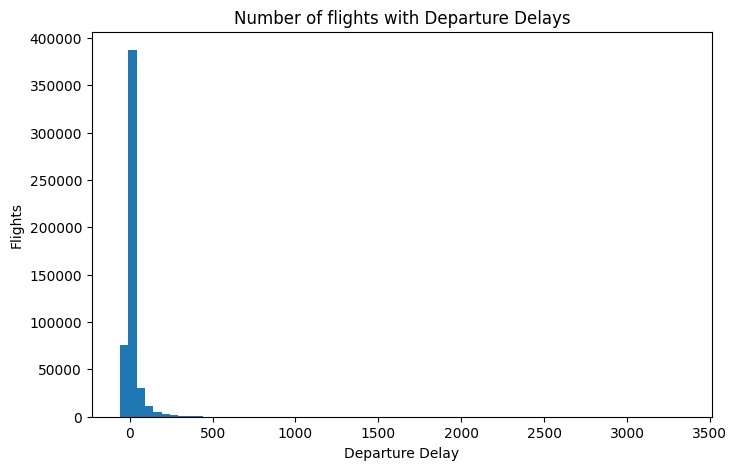

In [25]:
# Now all the values seem valid so we can continue
# Lets look at the DEFAULT histogram of departure delays first
import numpy as np
# default binsize
binsize = 50
#work out the best number of bins for the data- 3339 is the max DEP_DELAY in the sample data
bins = np.arange(cleanup3['DEP_DELAY'].min(), cleanup3['DEP_DELAY'].max()+binsize, binsize)
plt.figure(figsize=[8,5])
plt.hist(data = cleanup3, x='DEP_DELAY', bins=bins)
plt.title('Number of flights with Departure Delays')
plt.xlabel("Departure Delay")
plt.ylabel("Flights")
plt.show()

### Because the above chart is difficult to read, lets use a log scale to make it clearer

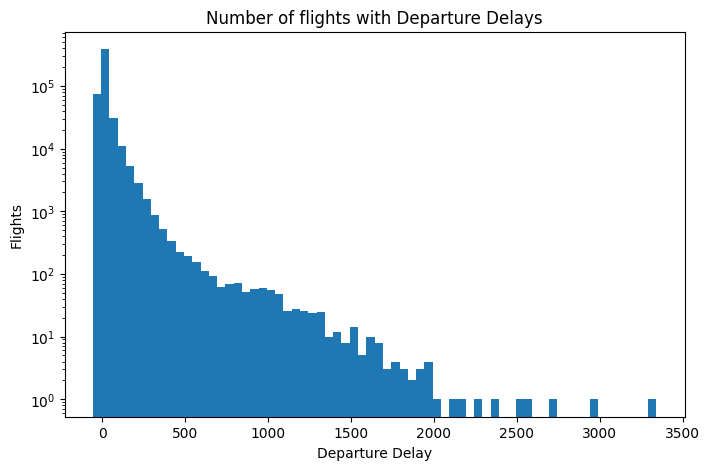

In [26]:
# Lets look at the log scale histogram of departure delays (as the default isnt helpful as there is a large value which skews the chart)
import numpy as np
# default binsize
binsize = 50
#work out the best number of bins for the data - 3339 is the max DEP_DELAY in the sample data
bins = np.arange(cleanup3['DEP_DELAY'].min(), cleanup3['DEP_DELAY'].max()+binsize, binsize)
plt.figure(figsize=[8,5])
plt.hist(data = cleanup3, x='DEP_DELAY', bins=bins, log=True)
plt.title('Number of flights with Departure Delays')
plt.xlabel("Departure Delay")
plt.ylabel("Flights")

plt.show()

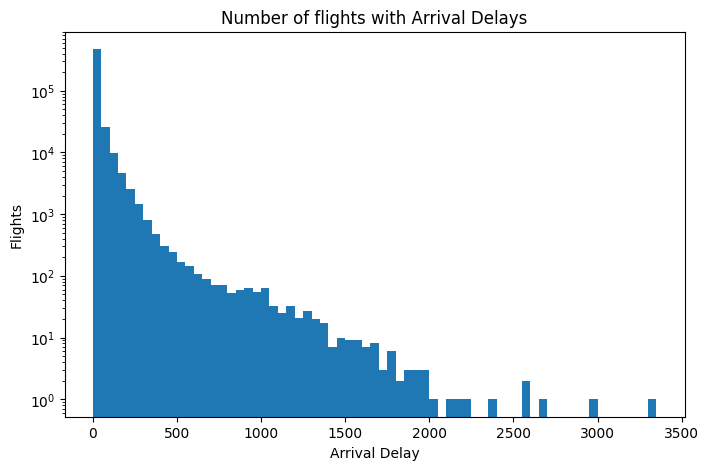

In [27]:
# Lets look at the log scale histogram of arrival delays 
import numpy as np
# default binsize
binsize = 50
#work out the best number of bins for the data - 3339 is the max DEP_DELAY in the sample data
bins = np.arange(cleanup3['ARR_DELAY_NEW'].min(), cleanup3['ARR_DELAY_NEW'].max()+binsize, binsize)
plt.figure(figsize=[8,5])
plt.hist(data = cleanup3, x='ARR_DELAY_NEW', bins=bins, log=True)

plt.xlabel("Arrival Delay")
plt.ylabel("Flights")
plt.title('Number of flights with Arrival Delays')
plt.show()

### Observation:  Yes, fewer flights have long delays than short delays (both Departure delays and Arrival delays)


### Question 2: How many flights were cancelled and delayed?

In [28]:
# first lets find the percentage of flights that were cancelled
print('Total flight records')
print(len(cleanup3))
print('Cancelled flights')
print(len(cleanup3[cleanup3['CANCELLED']==1]))
print('Percentage of flights cancelled')
ratio = len(cleanup3[cleanup3['CANCELLED']==1])/len(cleanup3)
print(f"{ratio:.2%}")

Total flight records
,542857
,Cancelled flights
,25635
,Percentage of flights cancelled
,4.72%


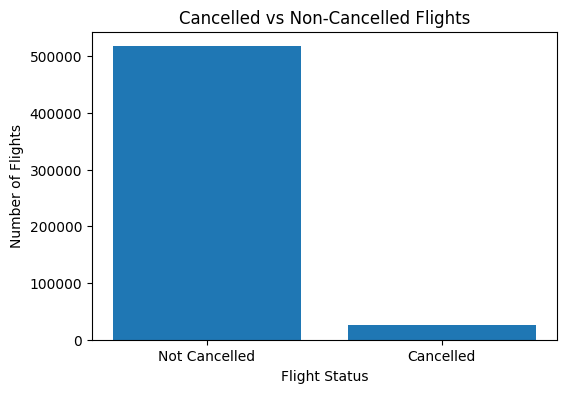

In [29]:
cancel_counts = cleanup3['CANCELLED'].value_counts().sort_index()

plt.figure(figsize=(6, 4))

plt.bar(
    ['Not Cancelled', 'Cancelled'],
    cancel_counts.values
)

plt.title('Cancelled vs Non-Cancelled Flights')
plt.xlabel('Flight Status')
plt.ylabel('Number of Flights')

plt.show()

### Observations:
### Discuss the distribution(s) of your variable(s) of interest. Were there any unusual points? Did you need to perform any transformations?

> Most flights (by far) are not cancelled.  Additionally, among the flights with departure delays, most flights have 0 or very small delays (mean departure delay of 13m) as we saw in the describe() earlier - even the bottom 50% are mostly not subject to departure delays. There are some very large delays but there are not many of them so they are outliers.
75% of Arrival delays are less than 9 minutes as seen in the describe earlier.  Again there are some larger outliers.

### Of the features you investigated, were there any unusual distributions? Did you perform any operations on the data to tidy, adjust, or change the form of the data? If so, why did you do this?

> I removed any arrival delay values that were null if the flight was not cancelled because it was difficult to guess what an arrival delay of null meant in such situations.  I used a log scale histogram to make it clearer to see the pattern in the data.  There were some very large delays but we have to assume that the number of minutes entered is correct for those.  

### Question 3 - What is the correlation (if any) between Departure Delays and Arrival Delays?

#### Bivariate Exploration

> In this section, I investigate relationships between pairs of variables in my data. I will make sure the variables that I cover here have been introduced in some fashion in the previous section (univariate exploration).

> **Rubric Tip**: This part (Bivariate Exploration) will include at least one scatter plot, one box plot, and at least one clustered bar chart or heat map.

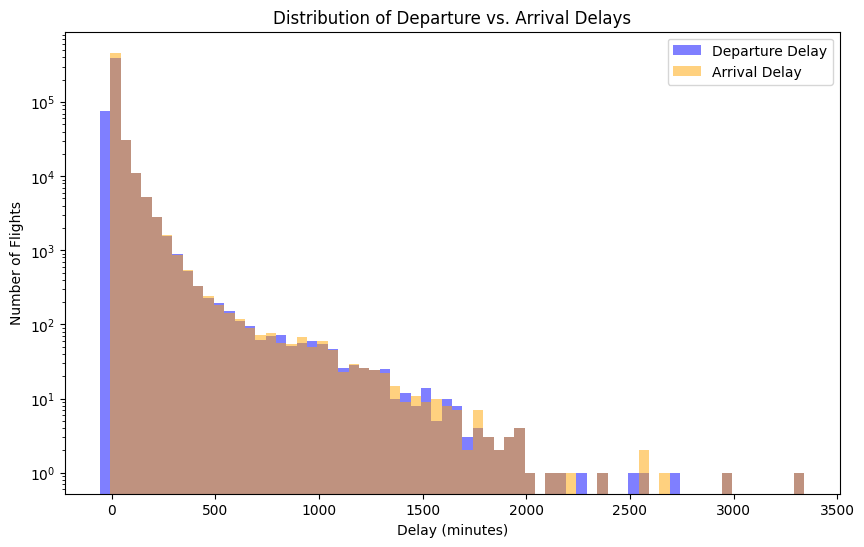

In [30]:
import numpy as np
import matplotlib.pyplot as plt

binsize = 50

# Use the same bins for both variables so they're directly comparable
bins = np.arange(
    min(cleanup3['DEP_DELAY'].min(), cleanup3['ARR_DELAY_NEW'].min()),
    max(cleanup3['DEP_DELAY'].max(), cleanup3['ARR_DELAY_NEW'].max()) + binsize,
    binsize
)

plt.figure(figsize=[10, 6])

# Departure delays
plt.hist(
    cleanup3['DEP_DELAY'],
    bins=bins,
    log=True,
    alpha=0.5,
    color='blue',
    label='Departure Delay'
)

# Arrival delays
plt.hist(
    cleanup3['ARR_DELAY_NEW'],
    bins=bins,
    log=True,
    alpha=0.5,
    color='orange',
    label='Arrival Delay'
)

plt.xlabel("Delay (minutes)")
plt.ylabel("Number of Flights")
plt.title("Distribution of Departure vs. Arrival Delays")
plt.legend()

plt.show()


### This bivariate graph shows that my suspicion that if there is a departure delay, it is likely there will be an arrival delay around the same value (positive relationship between departure delay and arrival delay) is probably true but this is not the best way to show it - so lets try a different kind of chart?

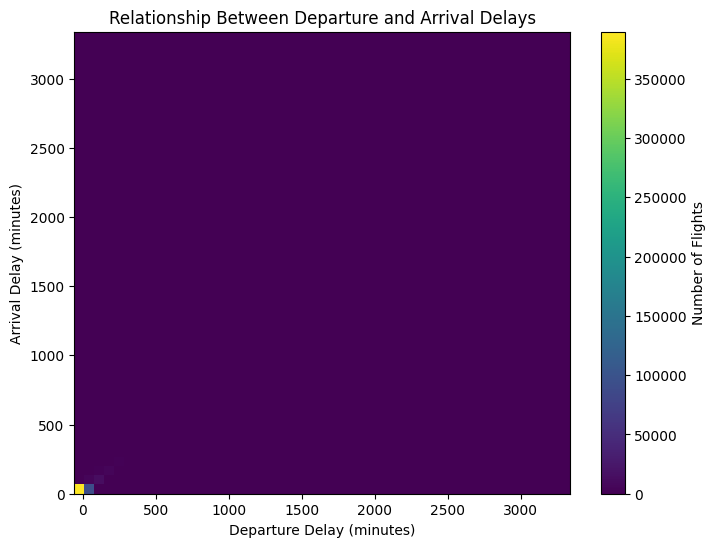

In [31]:
# a 2d histogram?
# Remove rows where either departure or arrival delay is missing
delay_data = cleanup3[['DEP_DELAY', 'ARR_DELAY_NEW']].dropna()

plt.figure(figsize=[8, 6])

plt.hist2d(
    delay_data['DEP_DELAY'],
    delay_data['ARR_DELAY_NEW'],
    bins=50,
    cmap='viridis'
)

plt.xlabel("Departure Delay (minutes)")
plt.ylabel("Arrival Delay (minutes)")
plt.title("Relationship Between Departure and Arrival Delays")

plt.colorbar(label="Number of Flights")

plt.show()


### The above chart does not show the values very well so lets try another approach

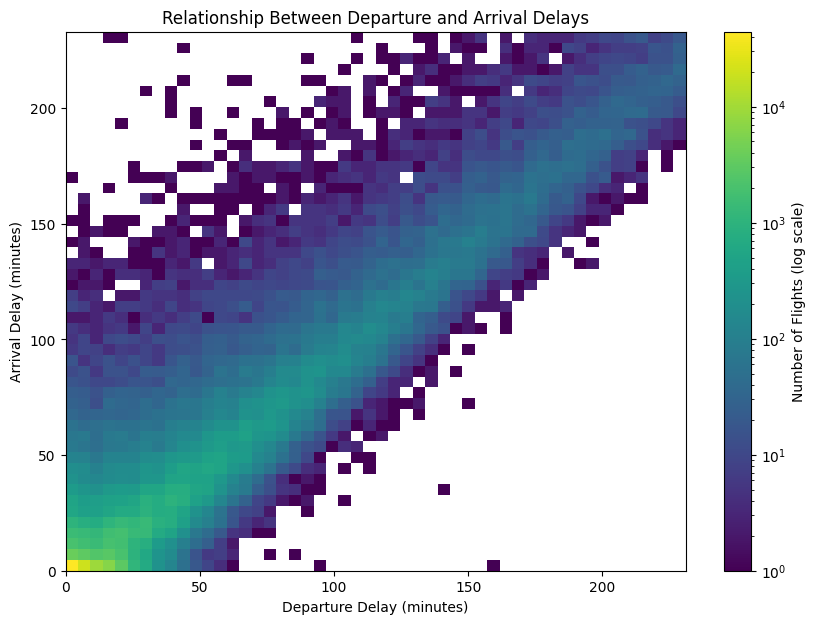

In [32]:
# hist2d with adjust for data - use LogNorm to show the relationship better, take 99%
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

delay_data = cleanup3[['DEP_DELAY', 'ARR_DELAY_NEW']].dropna()

dep_limit = delay_data['DEP_DELAY'].quantile(0.99)
arr_limit = delay_data['ARR_DELAY_NEW'].quantile(0.99)

plt.figure(figsize=[10, 7])

plt.hist2d(
    delay_data['DEP_DELAY'],
    delay_data['ARR_DELAY_NEW'],
    bins=50,
    range=[[0, dep_limit], [0, arr_limit]],
    cmap='viridis',
    norm=LogNorm()
)

plt.xlabel("Departure Delay (minutes)")
plt.ylabel("Arrival Delay (minutes)")
plt.title("Relationship Between Departure and Arrival Delays")

plt.colorbar(label="Number of Flights (log scale)")

plt.show()


### Still not sure I like this enough - anyhow we have to use a scatterplot 
### so let's see if it shows relationships better

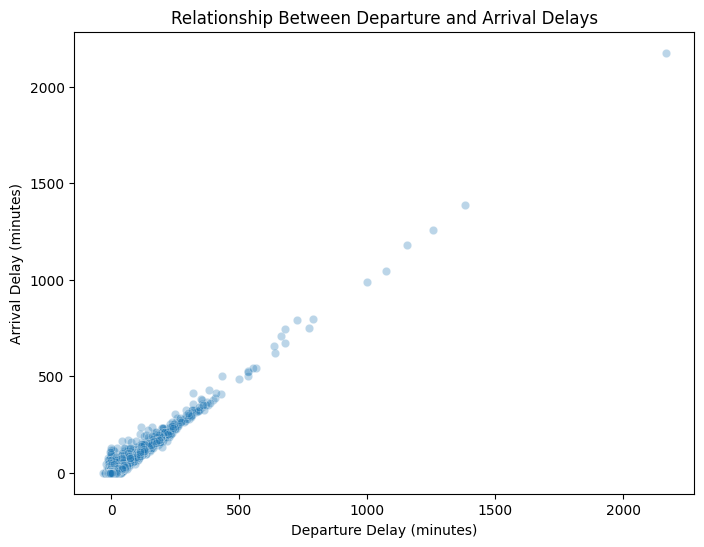

In [33]:
# Take a sample to prevent overplotting
scatter_data = cleanup3[
    ['DEP_DELAY', 'ARR_DELAY_NEW']
].dropna().sample(
    10000,
    random_state=42
)

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=scatter_data,
    x='DEP_DELAY',
    y='ARR_DELAY_NEW',
    alpha=0.3
)

plt.xlabel('Departure Delay (minutes)')
plt.ylabel('Arrival Delay (minutes)')
plt.title('Relationship Between Departure and Arrival Delays')

plt.show()

### This scatterplot is much better but only includes a sample 


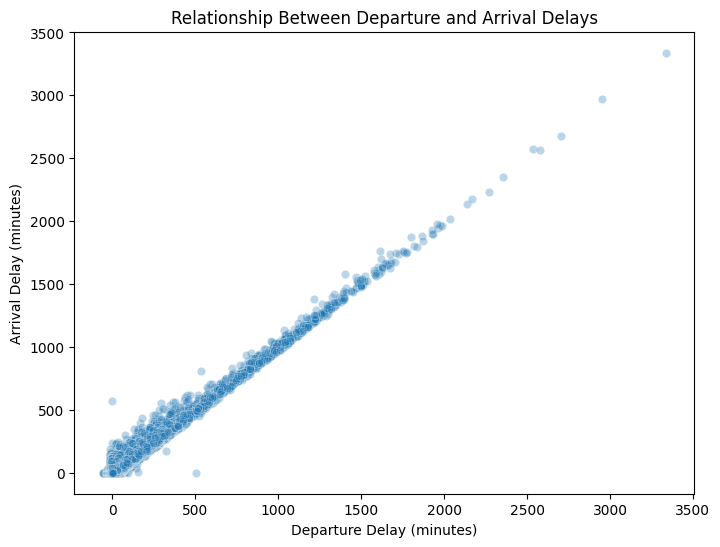

In [34]:
# Take a sample to prevent overplotting
scatter_data = cleanup3[
    ['DEP_DELAY', 'ARR_DELAY_NEW']
].dropna()

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=scatter_data,
    x='DEP_DELAY',
    y='ARR_DELAY_NEW',
    alpha=0.3
)

plt.xlabel('Departure Delay (minutes)')
plt.ylabel('Arrival Delay (minutes)')
plt.title('Relationship Between Departure and Arrival Delays')

plt.show()

#### I like this scatterplot much better as it clearly shows the relationship 
#### (positive) between Departure Delay and Arrival delay - 
#### BUT this could be considered overplotting


#### Here I talk about some of the relationships observed in this part of the investigation. How did the feature(s) of interest vary with other features in the dataset?

#### It is very clear that there is a POSITIVE relationship between Departure Delay 
#### and Arrival Delay:
#### Flights with 0 Departure Delay often have low Arrival Delay minutes.  
#### As Departure Delay grows, Arrival Delay grows too
#### Of course it is not always the same delay, and 
#### tends to a slightly higher Arrival Delay than Departure Delay
#### some flights make up the time so the Departure Delay is higher 
#### than the Arrival Delay but these are outliers.

### Did you observe any interesting relationships between the other features (not the main feature(s) of interest)?

### Outliers made it difficult to see the pattern at first, as the largest number of minutes was very high.  Using LogNorm and 99% made it easier to see the underlying trends/patterns

### Question 4:  What do delays look like by selected airports
#### Let's see what delays look like by airport
#### First Departure delays by airport (let's select four airports)

In [35]:
#lets see the name of some of the airports
print(cleanup3[['ORIGIN']].drop_duplicates().head(60))



      ORIGIN
,0        ABQ
,172      ALB
,256      AMA
,258      ANC
,263      ATL
,769      AUS
,1605     AVL
,1687     AVP
,1738     BDL
,1995     BFL
,2052     BHM
,2098     BNA
,2842     BOI
,2918     BOS
,4180     BTV
,4206     BUF
,4337     BUR
,4399     BWI
,4680     BZN
,4763     CHS
,5092     CID
,5198     CLE
,5460     CLT
,14380    CMH
,14710    COS
,14765    CVG
,14994    DCA
,17441    DEN
,18087    DFW
,31126    DSM
,31367    DTW
,31782    ECP
,31783    EGE
,31995    ELP
,32217    EUG
,32279    EWR
,32820    EYW
,32998    FAT
,33176    FLL
,33917    FSD
,33942    GEG
,34035    GRR
,34242    GSO
,34304    GSP
,34409    HDN
,34441    HNL
,34668    IAD
,34754    IAH
,35343    ICT
,35366    ILM
,35606    IND
,36036    JAC
,36110    JAX
,36609    JFK
,37870    KOA
,37968    LAS
,39031    LAX
,41351    LBB
,41382    LEX
,41417    LGA


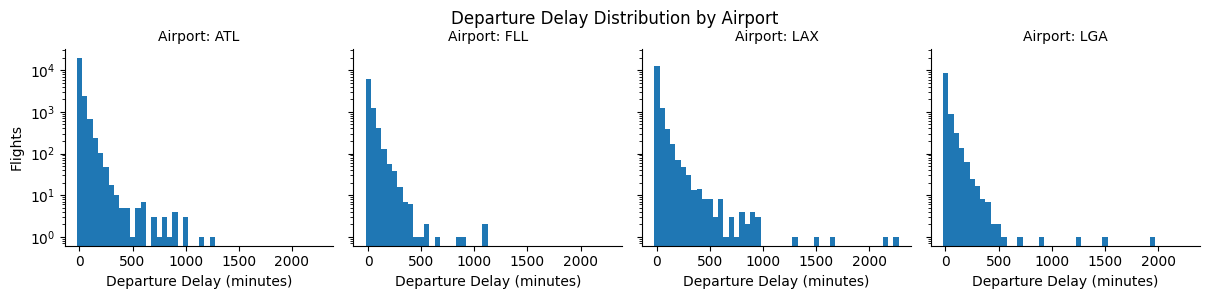

In [36]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Filter to four airports just so that it does not take forever to produce the facets grid
multivariate = cleanup3[
    cleanup3['ORIGIN'].isin(['ATL', 'FLL','LGA', 'LAX'])
].copy()

# Set bin size
binsize = 50

# Create the same bins for all four airports
bins = np.arange(
    multivariate['DEP_DELAY'].min(),
    multivariate['DEP_DELAY'].max() + binsize,
    binsize
)

# Create the facets
g = sns.FacetGrid(
    multivariate,
    col='ORIGIN',
    col_wrap=4,
    height=3,
    sharex=True,
    sharey=True
)

# Add histogram
g.map(
    plt.hist,
    'DEP_DELAY',
    bins=bins,
    log=True
)

# Labels and title
g.set_axis_labels("Departure Delay (minutes)", "Flights")
g.set_titles("Airport: {col_name}")

plt.subplots_adjust(top=0.85)
g.fig.suptitle("Departure Delay Distribution by Airport")

plt.show()



### Lets look at a box plot for this


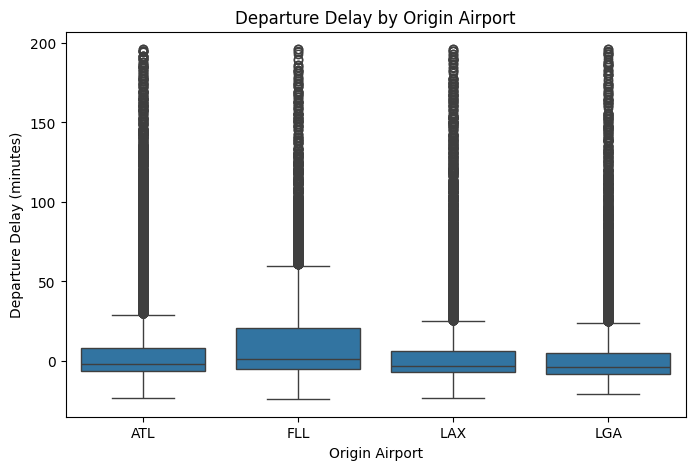

In [37]:
airports = ['ATL', 'FLL', 'LAX', 'LGA']

box_data = cleanup3[
    cleanup3['ORIGIN'].isin(airports)
].copy()

# Restrict display to the 99th percentile so extreme
# outliers do not make the main distributions unreadable
limit = box_data['DEP_DELAY'].quantile(0.99)

box_data = box_data[
    box_data['DEP_DELAY'] <= limit
]

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=box_data,
    x='ORIGIN',
    y='DEP_DELAY'
)

plt.xlabel('Origin Airport')
plt.ylabel('Departure Delay (minutes)')
plt.title('Departure Delay by Origin Airport')

plt.show()

#### Observations:
#### Box plot illustrates better that the four airports generally have 
#### very small delays but the results are very right skewed with large outlier delays. 
#### FLL airport stands out in the box plot - it clearly has higher typical delays but also greater 
#### variability in departure delays.
#### Note that the other three airports seem to have similar distributions - including some flights that leave early!  But all four have considerable outliers too.
#### We should not forget that we are only looking at 99% of the data here; so the most extreme 1% delays will not be represented here!

#### Now let's examine ARRIVAL DELAYS for the same airports

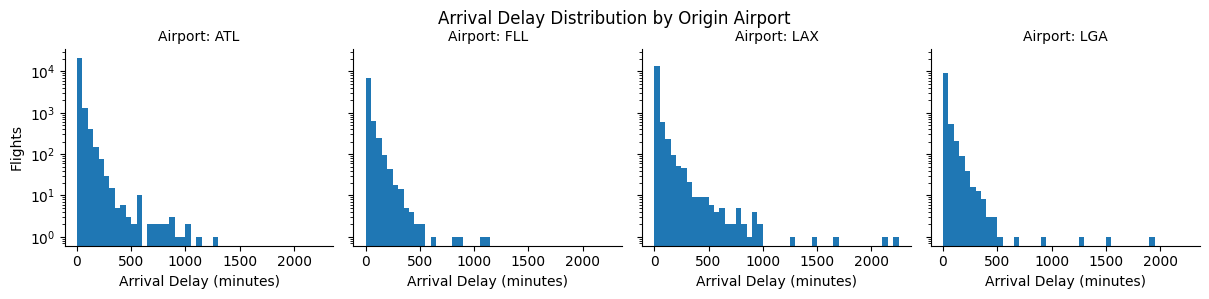

In [38]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# The four airports
airports = [ 'ATL', 'FLL', 'LAX', 'LGA']

# Filter to the four airports
arrival_data = cleanup3[
    cleanup3['ORIGIN'].isin(airports)
].copy()

# Set bin size
binsize = 50

# Create the same bins for all four airports
bins = np.arange(
    arrival_data['ARR_DELAY_NEW'].min(),
    arrival_data['ARR_DELAY_NEW'].max() + binsize,
    binsize
)

# Create the facets
g = sns.FacetGrid(
    arrival_data,
    col='ORIGIN',
    col_wrap=4,
    height=3,
    sharex=True,
    sharey=True
)

# Add histogram to each facet
g.map(
    plt.hist,
    'ARR_DELAY_NEW',
    bins=bins,
    log=True
)

# Labels and title
g.set_axis_labels("Arrival Delay (minutes)", "Flights")
g.set_titles("Airport: {col_name}")

plt.subplots_adjust(top=0.85)
g.fig.suptitle("Arrival Delay Distribution by Origin Airport")

plt.show()


## Multivariate Exploration

> Create plots of three or more variables to investigate your data even
further. Make sure that your investigations are justified, and follow from
your work in the previous sections.

> **Rubric Tip**: This part (Multivariate Exploration) should include at least one Facet Plot, and one Plot Matrix or Scatterplot with multiple encodings.

>**Rubric Tip**: Think carefully about how you encode variables. Choose appropriate color schemes, markers, or even how Facets are chosen. Also, do not overplot or incorrectly plot ordinal data.

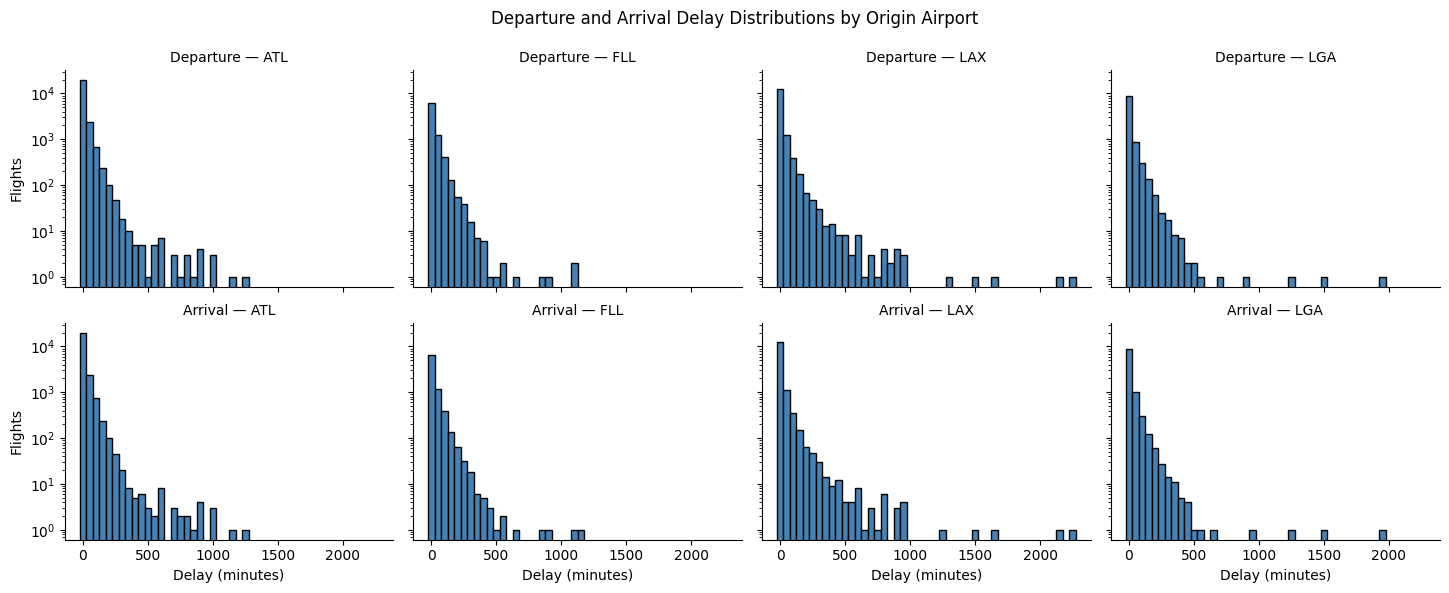

In [39]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# The four airports
airports = ['ATL', 'FLL', 'LAX', 'LGA']

# Filter to the four airports
plot_data = cleanup3[
    cleanup3['ORIGIN'].isin(airports)
].copy()

# Create a combined dataframe for departure and arrival delays
departure = plot_data[['ORIGIN', 'DEP_DELAY']].copy()
departure['Delay_Type'] = 'Departure'
departure = departure.rename(columns={'DEP_DELAY': 'Delay'})

arrival = plot_data[['ORIGIN', 'ARR_DELAY_NEW']].copy()
arrival['Delay_Type'] = 'Arrival'
arrival = arrival.rename(columns={'ARR_DELAY_NEW': 'Delay'})

# Combine the two datasets
facet_data = pd.concat([departure, arrival], ignore_index=True)

# Set bin size
binsize = 50

# Create common bins for both departure and arrival
bins = np.arange(
    facet_data['Delay'].min(),
    facet_data['Delay'].max() + binsize,
    binsize
)

# Create one FacetGrid
g = sns.FacetGrid(
    facet_data,
    row='Delay_Type',
    col='ORIGIN',
    col_order=airports,
    height=3,
    aspect=1.2,
    sharex=True,
    sharey=True
)

# Add histograms
g.map(
    plt.hist,
    'Delay',
    bins=bins,
    log=True,
    color='steelblue',
    edgecolor='black'
)

# Labels
g.set_axis_labels("Delay (minutes)", "Flights")
g.set_titles("{row_name} — {col_name}")

# Overall title
plt.subplots_adjust(top=0.88)
g.fig.suptitle(
    "Departure and Arrival Delay Distributions by Origin Airport"
)

plt.show()



### Observations:

### Talk about some of the relationships you observed in this part of the investigation. Were there features that strengthened each other in terms of looking at your feature(s) of interest?

> I see that typical Departure Delays from ATL and LAX tend to be larger on average, and arrival delays are therfore also larger (there are more between 500-1000 minutes) but with ATL there are  fewer larger outliers than LAX and LGA (which both have quite large outliers).

>LGA most flights are subject to smaller delays than 500 minutes but there are larger outliers (2000 mins) while LAX delays are larger on average AND they have larger outliers.

### Were there any interesting or surprising interactions between features?

> I thought ATL would have the most delays (as that is the airport I travel through mostly).  I am quite impressed that mostly all delays are the result of Departure delays - so that Arrival delay is usually not much more than the Departure delay - so that means pilots are making up time during the flight mostly I think.

### Now lets look at delays by Airline rather than by Airport
### Let's just choose 2 airlines - United Airlines (UA) and Delta (Dl)



In [40]:
#lets see the name of some of the airlines/carriers
print(cleanup3[['OP_UNIQUE_CARRIER']].drop_duplicates().head(60))

       OP_UNIQUE_CARRIER
,0                     AA
,76772                 AS
,103208                B6
,121317                DL
,200515                F9
,215897                G4
,224860                MQ
,249015                NK
,260930                OH
,280480                OO
,346648                UA
,410429                WN
,514431                YX


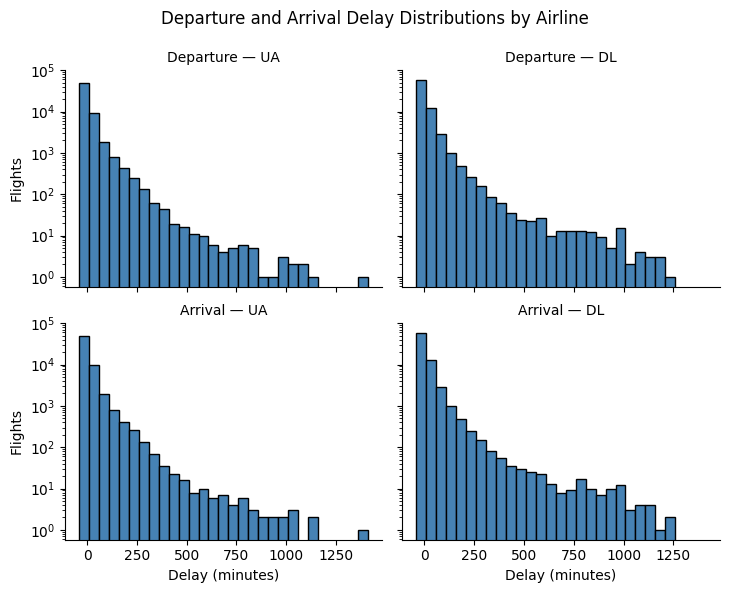

In [41]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# The two airlines
airlines = ['UA', 'DL']

# Filter to United and Delta
plot_data = cleanup3[
    cleanup3['OP_UNIQUE_CARRIER'].isin(airlines)
].copy()

# Create a combined dataframe for departure and arrival delays
departure = plot_data[['OP_UNIQUE_CARRIER', 'DEP_DELAY']].copy()
departure['Delay_Type'] = 'Departure'
departure = departure.rename(columns={'DEP_DELAY': 'Delay'})

arrival = plot_data[['OP_UNIQUE_CARRIER', 'ARR_DELAY_NEW']].copy()
arrival['Delay_Type'] = 'Arrival'
arrival = arrival.rename(columns={'ARR_DELAY_NEW': 'Delay'})

# Combine the two datasets
facet_data = pd.concat([departure, arrival], ignore_index=True)

# Set bin size
binsize = 50

# Create common bins for both departure and arrival
bins = np.arange(
    facet_data['Delay'].min(),
    facet_data['Delay'].max() + binsize,
    binsize
)

# Create one FacetGrid
g = sns.FacetGrid(
    facet_data,
    row='Delay_Type',
    col='OP_UNIQUE_CARRIER',
    col_order=airlines,
    height=3,
    aspect=1.2,
    sharex=True,
    sharey=True
)

# Add histograms
g.map(
    plt.hist,
    'Delay',
    bins=bins,
    log=True,
    color='steelblue',
    edgecolor='black'
)

# Labels
g.set_axis_labels("Delay (minutes)", "Flights")
g.set_titles("{row_name} — {col_name}")

# Overall title
plt.subplots_adjust(top=0.88)
g.fig.suptitle(
    "Departure and Arrival Delay Distributions by Airline"
)

plt.show()

### I want to use a multivariate illustration using a scatterplot here


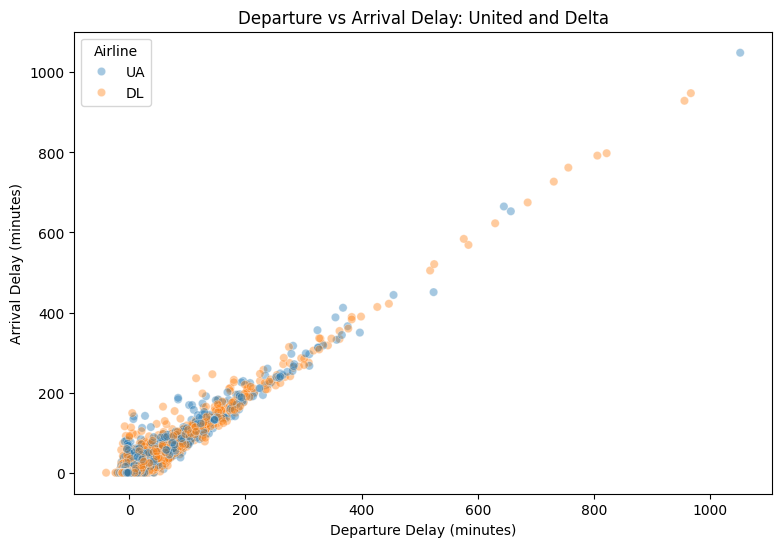

In [43]:
multi_data = cleanup3[
    cleanup3['OP_UNIQUE_CARRIER'].isin(['UA', 'DL'])
][
    ['DEP_DELAY', 'ARR_DELAY_NEW', 'OP_UNIQUE_CARRIER']
].dropna()

multi_sample = multi_data.sample(
    min(10000, len(multi_data)),
    random_state=42
)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=multi_sample,
    x='DEP_DELAY',
    y='ARR_DELAY_NEW',
    hue='OP_UNIQUE_CARRIER',
    alpha=0.4
)

plt.xlabel('Departure Delay (minutes)')
plt.ylabel('Arrival Delay (minutes)')
plt.title(
    'Departure vs Arrival Delay: United and Delta'
)

plt.legend(title='Airline')

plt.show()

### Observations:
### This shows departure delay and arrival delay by the two different airlines using color.  It shows  a lot of similarity between the airlines in the relation of departure delay to arrival delay.
### From these two visualizations, as I had suspected, Delta has more delays than United Airlines - very clearly shown in the first visualization, but still visible in the scatterplot here - however, that could be because Delta has more flights overall?  So we need to check whether Delta's delay RATE is higher than United Airlines or not too.  One way to check that is shown below.


,OP_UNIQUE_CARRIER,Total_Flights,Delayed_Flights,Delay_Rate,Delay_Type,Bar
0,DL,75997,14676,19.311289,Departure,
1,UA,62218,10409,16.729885,Departure,
2,DL,75939,15000,19.752696,Arrival,
3,UA,62176,11166,17.958698,Arrival,


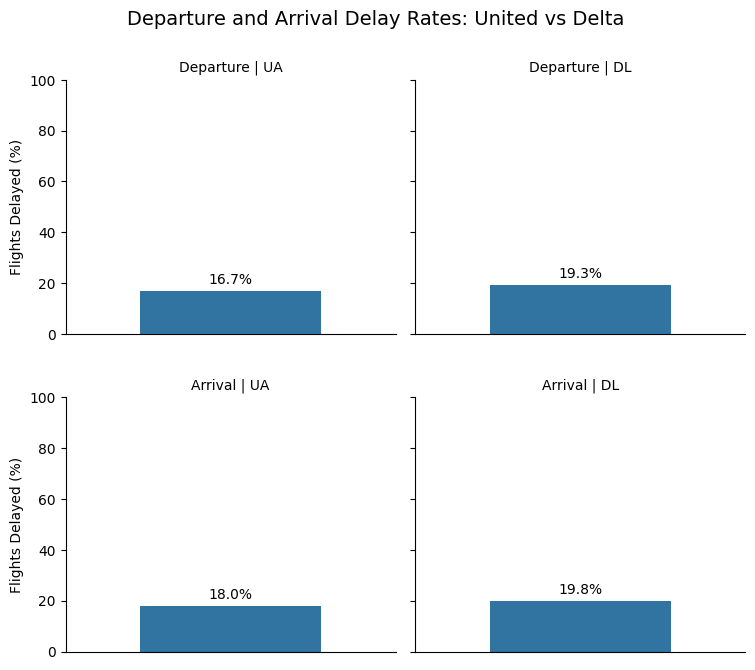

In [42]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# =======================================================
# UNITED vs DELTA - DEPARTURE AND ARRIVAL DELAY RATES
# =======================================================

airlines = ['UA', 'DL']

# -------------------------------------------------------
# 1. Filter to United and Delta
# -------------------------------------------------------

plot_data = cleanup3[
    cleanup3['OP_UNIQUE_CARRIER'].isin(airlines)
].copy()


# -------------------------------------------------------
# 2. Calculate DEPARTURE delay rates
# -------------------------------------------------------

departure = plot_data[
    ['OP_UNIQUE_CARRIER', 'DEP_DELAY']
].dropna().copy()

# 15 minutes or more = delayed
departure['Delayed'] = departure['DEP_DELAY'] >= 15

departure_rates = (
    departure
    .groupby('OP_UNIQUE_CARRIER')
    .agg(
        Total_Flights=('Delayed', 'size'),
        Delayed_Flights=('Delayed', 'sum')
    )
    .reset_index()
)

departure_rates['Delay_Rate'] = (
    departure_rates['Delayed_Flights']
    / departure_rates['Total_Flights']
    * 100
)

departure_rates['Delay_Type'] = 'Departure'


# -------------------------------------------------------
# 3. Calculate ARRIVAL delay rates
# -------------------------------------------------------

arrival = plot_data[
    ['OP_UNIQUE_CARRIER', 'ARR_DELAY_NEW']
].dropna().copy()

# 15 minutes or more = delayed
arrival['Delayed'] = arrival['ARR_DELAY_NEW'] >= 15

arrival_rates = (
    arrival
    .groupby('OP_UNIQUE_CARRIER')
    .agg(
        Total_Flights=('Delayed', 'size'),
        Delayed_Flights=('Delayed', 'sum')
    )
    .reset_index()
)

arrival_rates['Delay_Rate'] = (
    arrival_rates['Delayed_Flights']
    / arrival_rates['Total_Flights']
    * 100
)

arrival_rates['Delay_Type'] = 'Arrival'


# -------------------------------------------------------
# 4. Combine departure and arrival results
# -------------------------------------------------------

delay_rates = pd.concat(
    [departure_rates, arrival_rates],
    ignore_index=True
)

# Add a constant x value.
# We do NOT need airline as the x-axis because airline
# is already represented by the facet columns.
delay_rates['Bar'] = ''

# Show the calculated rates
display(delay_rates)


# -------------------------------------------------------
# 5. Create the 2 x 2 FacetGrid
#
#                  UA              DL
#
# Departure       RATE            RATE
#
# Arrival         RATE            RATE
#
# -------------------------------------------------------

g = sns.FacetGrid(
    delay_rates,
    row='Delay_Type',
    col='OP_UNIQUE_CARRIER',
    row_order=['Departure', 'Arrival'],
    col_order=['UA', 'DL'],
    height=3.5,
    aspect=1.1,
    sharex=True,
    sharey=True
)


# -------------------------------------------------------
# 6. Draw ONE centered bar in each facet
# -------------------------------------------------------

g.map_dataframe(
    sns.barplot,
    x='Bar',
    y='Delay_Rate',
    width=0.55
)


# -------------------------------------------------------
# 7. Use the same percentage scale for all facets
# -------------------------------------------------------

g.set(
    ylim=(0, 100)
)


# -------------------------------------------------------
# 8. Labels
# -------------------------------------------------------

g.set_axis_labels(
    "",
    "Flights Delayed (%)"
)


# -------------------------------------------------------
# 9. Facet titles
# -------------------------------------------------------

g.set_titles(
    row_template="{row_name}",
    col_template="{col_name}"
)


# -------------------------------------------------------
# 10. Remove the unnecessary x-axis completely
# -------------------------------------------------------

for ax in g.axes.flat:
    ax.set_xticks([])
    ax.set_xlabel('')


# -------------------------------------------------------
# 11. Put the percentage above each bar
# -------------------------------------------------------

for ax in g.axes.flat:
    for container in ax.containers:
        ax.bar_label(
            container,
            fmt='%.1f%%',
            padding=3
        )


# -------------------------------------------------------
# 12. Overall title
# -------------------------------------------------------

g.fig.subplots_adjust(
    top=0.88,
    hspace=0.25
)

g.fig.suptitle(
    "Departure and Arrival Delay Rates: United vs Delta",
    fontsize=14
)


# -------------------------------------------------------
# 13. Display
# -------------------------------------------------------

plt.show()

### Observations:  
### So this confirms my suspicion that Delta's delay rate (both arrival and departure) is higher than United Airlines


## Conclusions
>Here is a summary of the main findings:
- Departure delays are the big factor in creating Arrival delays.
- FLL airport experiences more delays and variability of delays than other airports
    - ATL airport does have lots of delays under 1000 minutes but has few larger delays.  LGA delays include larger outliers also.  LAX delays are larger on average AND have larger outliers.
- Delta has more delays than United Airlines but this is due to Delta having more flights in total
- Delta also has a higher RATE of delays than United Airlines

>Details:

Flight delays in the January 2026 dataset selections were strongly right-skewed. Most flights experienced smaller departure and arrival delays; larger delays were usually outliers.

Departure and arrival delays were positively related: if flights had departure delays they often also had arrival delays although some flights recovered some of the departure delay during the journey.

Delay Distributions between the four selected airports showed a number of observations:
FLL typical departure delay was greater, and the delay variability was greater than ATL, LAX and LGA - clearly shown in the box-plot comparison.  All four airports had substantial positive-delay outliers.

Delta had more delayed flights than United, but comparing counts alone could be misleading because the airlines operated different numbers of flights. After calculating the proportion of flights delayed by at least 15 minutes, Delta also had a higher delay rate in this dataset. Delta's departure delay rate was approximately 19.3%, compared with 16.7% for United, while its arrival delay rate was approximately 19.8%, compared with approximately 18.0% for United. 

Reflection
I created a data exploration starting with individual variables (univariate) and progressing to relationships between two variables (bivariate) and finally to comparisons involving multiple variables (multi-variate). 

I had to adjust some of my work to account for null/missing delay values and also to cater for extreme outliers that skewed the data or made it difficult to see patterns in the data. Rather than assuming that extreme delays were errors, I assumed that they were correct, while using log scales and percentile views to make the data / patterns easier to understand.

One important finding from the exploration was that comparing absolute delay minutes between airlines can lead to misleading results. The initial visualizations showed more Delta delays than United delays, but this did not take into account for differences in the total number of flights. 

Calculating delay rates provided a more meaningful comparison. 

Further analysis
I limited my exploration to only two airlines and only four airports but the same principles could be used in future analysis to compare all airlines and airports.